# VietnamNet: phân loại tiêu đề tiếng Việt

**CO5177 · Text · Học kỳ 261**  
Huỳnh Thành Đạt (2570161) · Lương Minh Duy (2570083)

Dự đoán một trong 19 chuyên mục từ tiêu đề bài báo. So sánh baseline đa số, TF-IDF từ/ký tự với Linear SVM và PhoBERT đóng băng với logistic regression.

## 1. Môi trường

Run all chạy lại thí nghiệm và kiểm tra trên máy hiện tại. Dữ liệu, model và cache được lưu ngoài Git. Text tải PhoBERT khi chưa có cache; không gọi dịch vụ huấn luyện trả phí.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if not Path('configs/text.json').exists():
    target = Path('/content/CO5177-PFDAV')
    if not target.exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/dathuynh1108/CO5177-PFDAV.git', str(target)], check=True)
    os.chdir(target)
missing = [name for name in ['sklearn', 'pandas', 'pyarrow', 'torch', 'transformers', 'pyvi'] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-studies.txt'], check=True)
sys.path.insert(0, str(Path('src').resolve()))
import json, pandas as pd
from IPython.display import display, Image
from studies.evidence import ROOT, audit
print('Repository:', ROOT.name)

Repository: CO5177-PFDAV


## 2. Nguồn và chất lượng dữ liệu

Nguồn `dathuynh1108/vietnamnet-news`, revision cố định trong config, gồm 212.705 bài ở 19 tệp chuyên mục. Đọc toàn bộ corpus để kiểm tra dữ liệu, loại tiêu đề rỗng và nhóm trùng theo URL hoặc tiêu đề chuẩn hóa. Các nhóm có chuyên mục mâu thuẫn được loại. Tập mô hình gồm tối đa 400 tiêu đề mỗi lớp, tổng 7.600 mẫu; không trình bày đây là huấn luyện trên toàn bộ corpus.

In [2]:
from studies.text import prepare, run
config = json.loads((ROOT/'configs/text.json').read_text())
frame, data_info = prepare(config)
print({k:v for k,v in data_info.items() if k not in ['raw_class_counts','selected_class_counts']})
display(pd.DataFrame.from_dict(data_info['selected_class_counts'], orient='index', columns=['samples']))

{'raw_rows': 212705, 'empty_headlines_removed': 1167, 'conflicting_category_rows_removed': 3628, 'duplicate_rows_removed_after_conflicts': 296, 'unique_usable_rows': 207614, 'modeling_rows': 7600, 'max_per_class': 400, 'body_length_quantiles': {'0': 0.0, '0.25': 1750.0, '0.5': 2796.0, '0.75': 4160.0, '0.95': 6809.0, '1': 398169.0}, 'input': 'Headline only; URLs, body and category strings are excluded from model inputs', 'sampling': 'Deterministic capped cohort after full-corpus quality audit, not full-corpus training', 'duplicate_scope': 'Connected components of canonical URL OR normalized casefolded headline; conflicting-category components removed'}


,samples
ban-doc,400
bao-ve-nguoi-tieu-dung,400
bat-dong-san,400
chinh-tri,400
cong-nghe,400
dan-toc-ton-giao,400
doi-song,400
du-lich,400
giao-duc,400
kinh-doanh,400


## 3. Thiết lập và huấn luyện

Cùng tập 7.600 tiêu đề và split 70/15/15 cho mọi mô hình. URL và tên chuyên mục không được đưa vào input. Tiêu đề được tách từ bằng PyVi; TF-IDF chỉ fit train. PhoBERT VinAI revision cố định không cập nhật trọng số, mean pooling theo attention mask, tối đa 128 token. C của SVM/logistic regression chọn trong {0.5, 1, 2} bằng macro-F1 validation.

In [3]:
summary = run()

PhoBERT features: 16/7600


PhoBERT features: 528/7600


PhoBERT features: 1040/7600


PhoBERT features: 1552/7600


PhoBERT features: 2064/7600


...

PhoBERT features: 7184/7600


majority: validation macro-F1=0.0053


word: validation macro-F1=0.6326


character: validation macro-F1=0.6435


phobert: validation macro-F1=0.7625


## 4. Kết quả trên tập test

Accuracy và macro-F1 được tính từ predictions của tập test đã cố định. Thời gian dưới đây gồm fit và đánh giá validation của các ứng viên; riêng Text không tính thời gian mã hóa PhoBERT vào thời gian fit classifier.

In [4]:
display(pd.DataFrame([{'model':r['name'], 'C':r['selected_C'], 'validation_macro_f1':r['validation']['macro_f1'], 'test_accuracy':r['test']['accuracy'], 'test_macro_f1':r['test']['macro_f1'], 'fit_validation_seconds':r['fit_and_validation_seconds']} for r in summary['models']]))

,model,C,validation_macro_f1,test_accuracy,test_macro_f1,fit_validation_seconds
0,Majority baseline,NaN,0.005263,0.052632,0.005263,0.015441
1,Word TF-IDF + Linear SVM,0.5,0.632560,0.663158,0.658224,0.609381
2,Character TF-IDF + Linear SVM,0.5,0.643501,0.672807,0.667648,2.243765
3,Frozen PhoBERT + Logistic regression,0.5,0.762510,0.775439,0.773780,2.565267


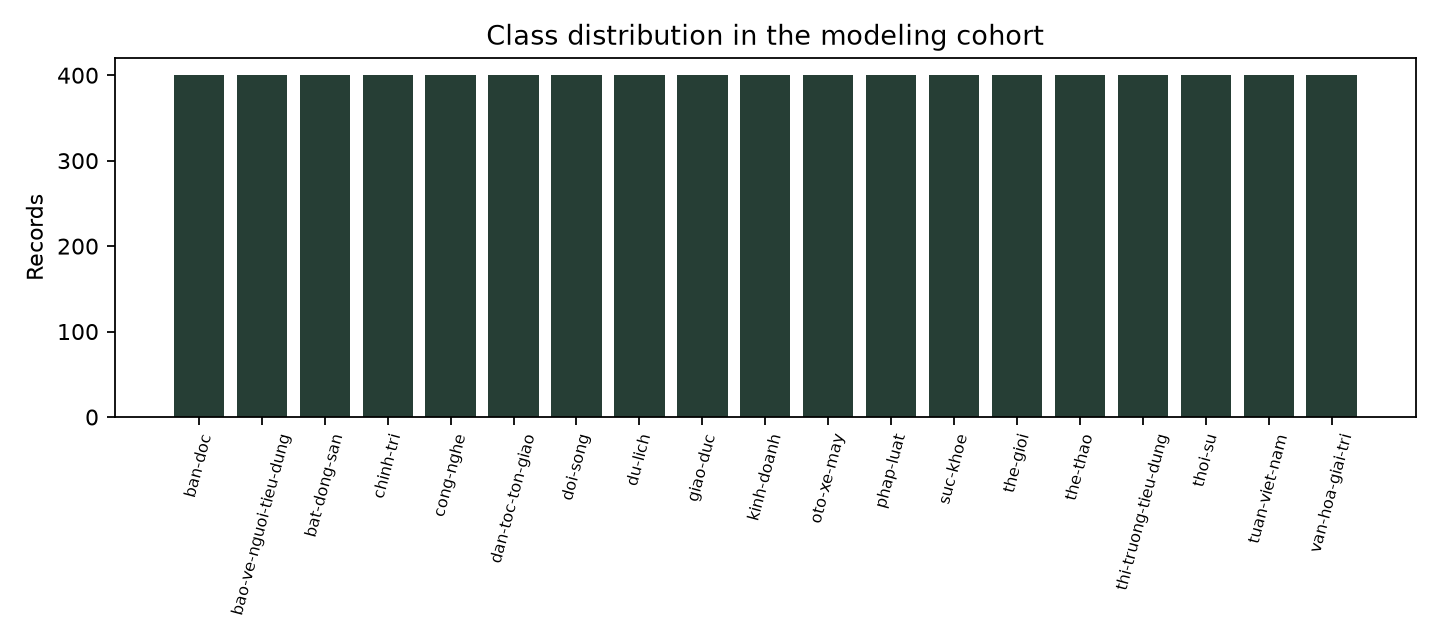

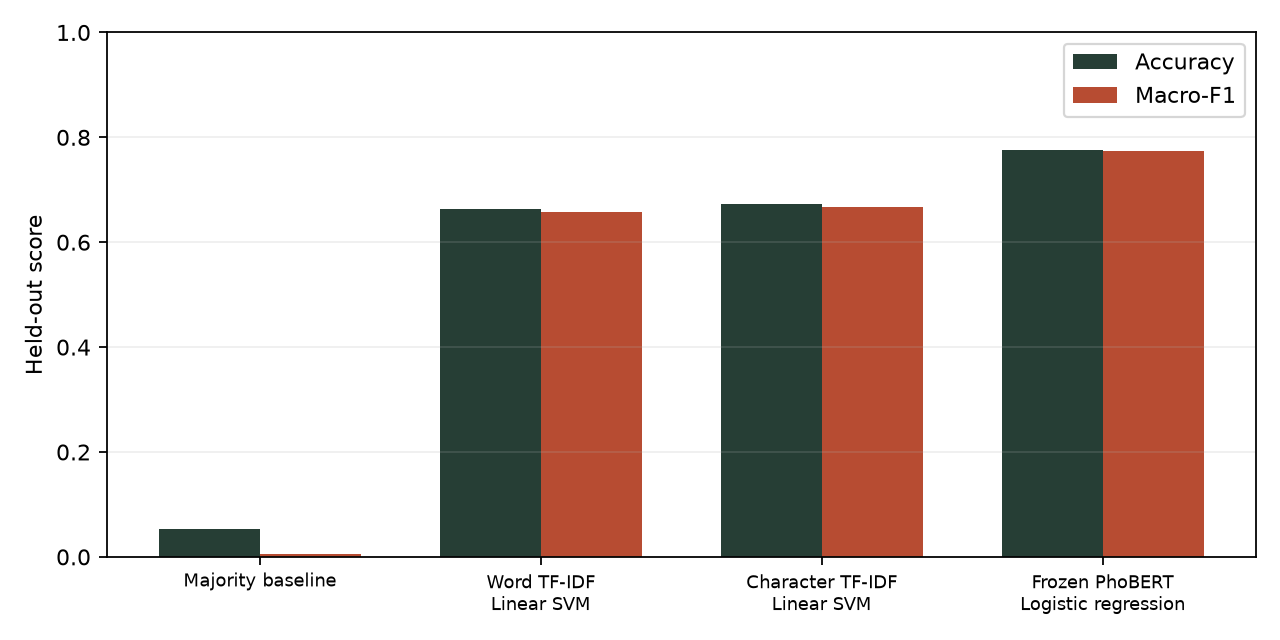

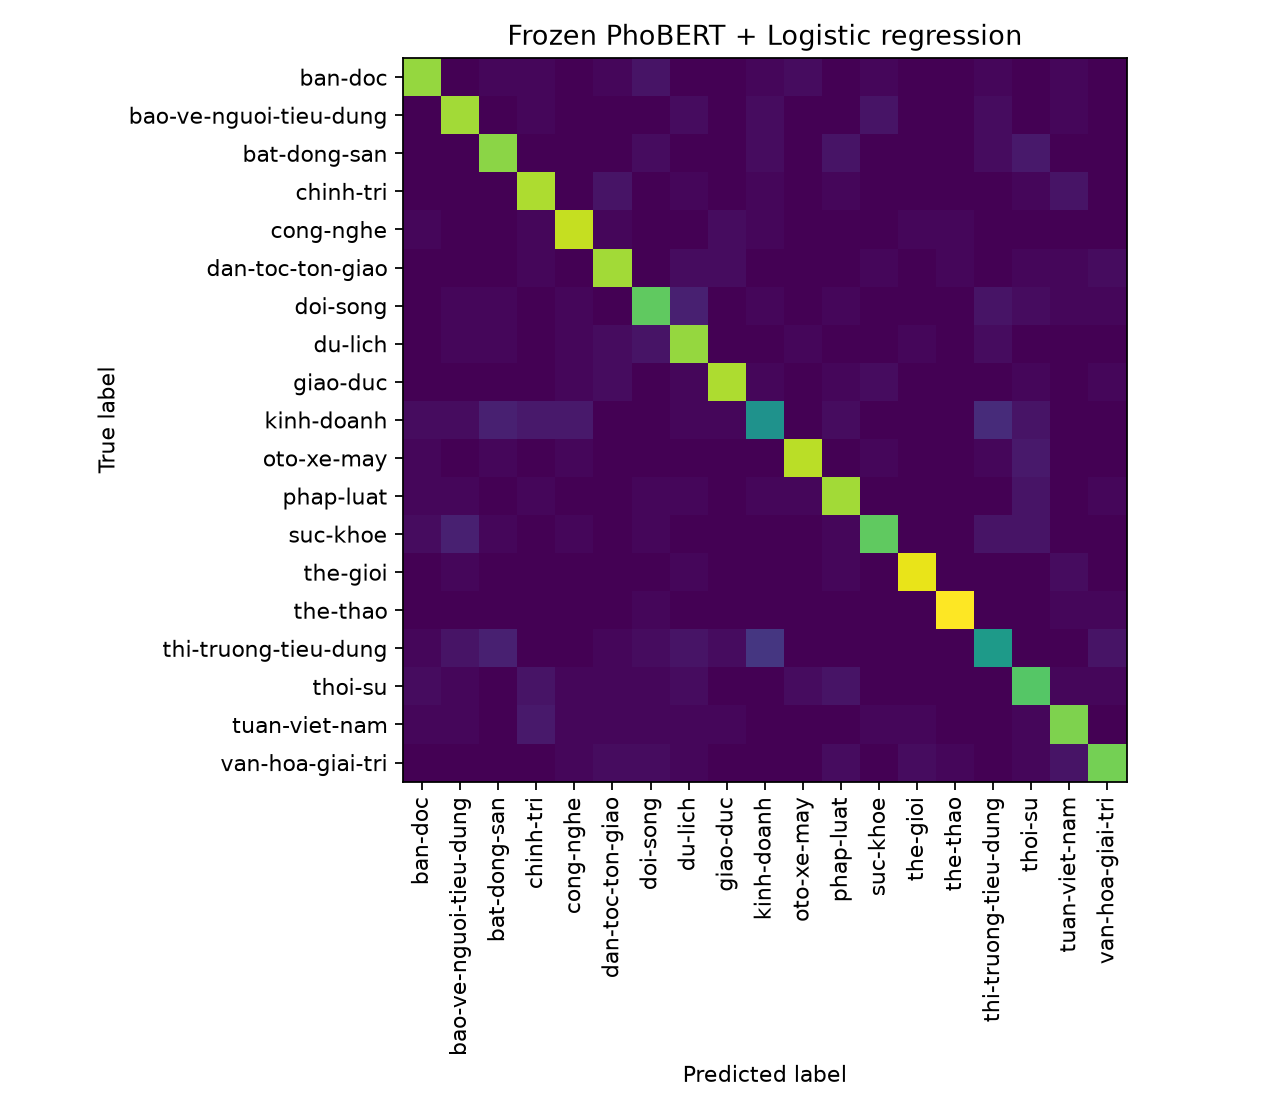

In [5]:
for figure in ['class_counts', 'scores', 'confusion']:
    display(Image(filename=f'reports/text/generated/{figure}.png', width=760))

## 5. Phân tích và giới hạn

In [6]:
print(summary['pretrained'])
errors = pd.read_csv('reports/text/generated/errors.csv')
display(errors.head(10))
chosen = max(summary['models'], key=lambda r:r['validation']['macro_f1'])
per_class = chosen['test']['per_class']
display(pd.DataFrame([{'category':name, **per_class[name]} for name in summary['classes']]).sort_values('f1-score').head(8))

{'model': 'vinai/phobert-base-v2', 'revision': '86cd7fd4c148980922ac11a2cf5e257f2ba639e1', 'device': 'mps', 'feature_cache_key': 'bdc0521dfbbe93ecc863011dde7ca0af3ad6ebf1777d2256a545abfb3157b30e', 'encoder_source_sha256': 'b5bdbb568d8a57bb8545be75dca31d45cf90a2906eb97f2da5e44c08b0c6e88c', 'features_sha256': 'b193895d9044bfd62b672aaed436c23bafe000fb320082eb7a82562e701c9501', 'rows': 7600, 'max_length': 128, 'batch_size': 16, 'pooling': 'Attention-mask mean including BOS/EOS', 'frozen': True, 'model_artifacts_sha256': {'pytorch_model.bin': '7ba09eb4c244a5b3a49ad76d52d129ac085b61f5c6287de7f99508b02be589f9', 'config.json': '26d21a304fdea8fada88e7c6b7c7fef15c902c690bfb0fa47f60bdb61c68307a', 'vocab.txt': 'dffd7543c401fb6567253ae7c3313004532c33d062525250049c616544bad777', 'bpe.codes': '9dfe53fb8abbddd3387da99641c36e00bee757a3679aad9cf0a7cdc4b30f6ef8'}, 'segmentation': 'pyvi.ViTokenizer', 'truncated_headlines': 0, 'encoding_seconds': 19.190076958038844}


,id,url,category,prediction
0,581f63ce6fd3ec3846af31652400ccaea12b3f34b2d398...,https://vietnamnet.vn/sieu-giong-ha-noi-thien-...,tuan-viet-nam,thoi-su
1,1c07bf7fa7841f8b0b4babdd51d7c27c9fc4b10e081065...,https://vietnamnet.vn/hoa-si-kiem-5-000-ty-don...,van-hoa-giai-tri,cong-nghe
2,b77145bb82ce0d9a914ca42acca64792024df66db7a520...,https://vietnamnet.vn/vu-anh-tuan-dang-quang-n...,van-hoa-giai-tri,the-thao
3,e55bb281a17375d071daf512c58f75a52c48ae494f131c...,https://vietnamnet.vn/nam-2021-chuyen-nhuong-d...,bat-dong-san,kinh-doanh
4,0dce4a7b9bbed7eaf273facdfec1167ce99e9133e544ee...,https://vietnamnet.vn/cap-doi-2-nam-chinh-phuc...,du-lich,doi-song
5,e457b7118055cc6feb722e43eb238990f441549b6978e9...,https://vietnamnet.vn/dung-3-ty-chuyen-nham-mu...,bat-dong-san,kinh-doanh
6,29b2a6efe12c7b91fca9ea3e163088ba513aa6a664dada...,https://vietnamnet.vn/nhung-thu-pho-truong-va-...,the-gioi,bao-ve-nguoi-tieu-dung
7,dc6b6961cfb361c5c346dbd8c190fa75453487d9d48e47...,https://vietnamnet.vn/kich-ban-nao-cho-nhung-n...,the-gioi,tuan-viet-nam
8,d52f711d2a7c585c7331d068141166f6cf3d128fc16a89...,https://vietnamnet.vn/tphcm-lam-ro-vai-tro-can...,kinh-doanh,thoi-su
9,a6cbb124b5d23b1446947b4b58758096b2c80ad863526c...,https://vietnamnet.vn/q-a-co-nen-giau-cha-me-v...,suc-khoe,ban-doc


,category,precision,recall,f1-score,support
9,kinh-doanh,0.604167,0.483333,0.537037,60.0
15,thi-truong-tieu-dung,0.596154,0.516667,0.553571,60.0
16,thoi-su,0.636364,0.700000,0.666667,60.0
6,doi-song,0.716667,0.716667,0.716667,60.0
7,du-lich,0.695652,0.800000,0.744186,60.0
17,tuan-viet-nam,0.766667,0.766667,0.766667,60.0
12,suc-khoe,0.826923,0.716667,0.767857,60.0
2,bat-dong-san,0.758065,0.783333,0.770492,60.0


Nhãn chuyên mục là nhãn nguồn, có thể giao nhau về nội dung. Tập cân bằng 7.600 tiêu đề khác phân bố của toàn bộ corpus; chưa kiểm tra near duplicates hoặc chia theo thời gian. Chỉ dùng tiêu đề, không suy diễn khả năng đọc toàn bài. PhoBERT là feature extractor cố định; đây không phải fine-tuning backbone. Một split và seed không mô tả biến thiên giữa nhiều lượt chạy.

## 6. Kiểm tra kết quả

Audit kiểm tra checksum, split và tính lại accuracy, macro-F1, confusion từ predictions. Classifier được lưu ở `runs/`; bản báo cáo PDF và LaTeX nằm riêng theo track.

In [7]:
audit('text', check_models=True)

{'track': 'text', 'models': 4, 'test_rows': 1140, 'verified_artifacts': 9}

Báo cáo sử dụng AI được đính kèm tại `AI_USE_REPORT.md` trong repository.